In [1]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\vijay\AppData\Local\Programs\Python\Python314\python.exe
3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]


In [2]:
%pip install pandas matplotlib seaborn nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

print("All libraries imported successfully!")

All libraries imported successfully!


# Amazon Customer Review Sentiment Analysis

## 1. Loading the Dataset

In this project, we analyze Amazon customer reviews to understand the sentiment expressed in the review text.

The dataset contains customer reviews along with information such as product ID, user ID, rating score, review summary, and review text.

In [4]:
df = pd.read_csv("../data/Reviews.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (568454, 10)


## 2. Understanding the Dataset

Before performing sentiment analysis, we first examine the structure of the dataset.

We will:
- Check the first few records
- Identify the available columns
- Check the data types
- Find missing values
- Understand the basic statistics

In [5]:
# Display the first 5 rows of the dataset

df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


## 2.1 Dataset Structure

Next, we examine the column names and data types.

This helps us understand which columns contain numerical information and which columns contain text that can be used for sentiment analysis.

In [6]:
# Display column names and their data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


## 2.2 Rating Distribution

The `Score` column represents the customer's rating from 1 to 5.

We will examine how many reviews belong to each rating category. This helps us understand the overall distribution of customer ratings in the dataset.

In [7]:
# Count the number of reviews for each rating

score_counts = df["Score"].value_counts().sort_index()

score_counts

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64

## 2.3 Rating Distribution Visualization

The rating distribution shows how customers rated the products on a scale of 1 to 5.

A bar chart helps us visually compare the number of reviews received for each rating.

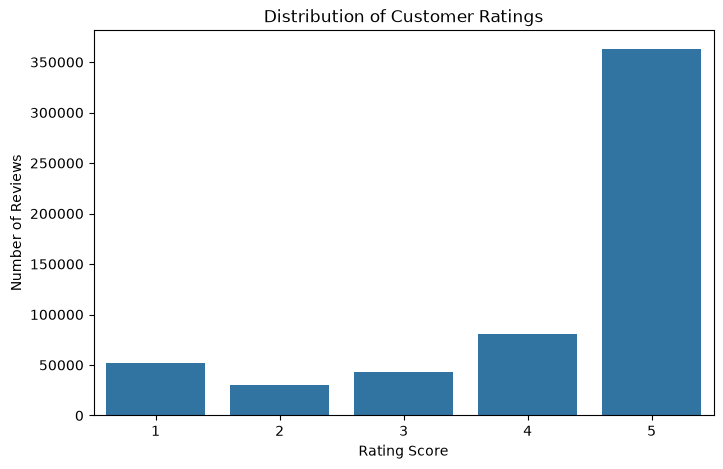

In [8]:
# Plot the distribution of customer ratings

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Score")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating Score")
plt.ylabel("Number of Reviews")

plt.show()

## 3. Creating Sentiment Labels

For this project, we classify customer reviews into three sentiment categories based on their ratings:

- **Positive:** Rating 4 or 5
- **Neutral:** Rating 3
- **Negative:** Rating 1 or 2

This classification provides a simple reference for understanding customer sentiment.

In [9]:
# Create sentiment labels based on the customer rating

def classify_sentiment(score):
    if score >= 4:
        return "Positive"
    elif score == 3:
        return "Neutral"
    else:
        return "Negative"


df["Sentiment"] = df["Score"].apply(classify_sentiment)

# Display a few examples
df[["Score", "Sentiment", "Summary", "Text"]].head()

,Score,Sentiment,Summary,Text
0,5,Positive,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,1,Negative,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,4,Positive,"""Delight"" says it all",This is a confection that has been around a fe...
3,2,Negative,Cough Medicine,If you are looking for the secret ingredient i...
4,5,Positive,Great taffy,Great taffy at a great price. There was a wid...


## 3.1 Sentiment Distribution

After assigning sentiment labels based on customer ratings, we calculate the number of reviews in each sentiment category.

This helps us understand the overall sentiment of the customer reviews.

In [10]:
# Count the number of reviews in each sentiment category

sentiment_counts = df["Sentiment"].value_counts()

sentiment_counts

Sentiment
Positive    443777
Negative     82037
Neutral      42640
Name: count, dtype: int64

## 3.2 Sentiment Distribution Visualization

The following chart shows the distribution of positive, negative, and neutral customer reviews.

This visualization helps us quickly compare the overall sentiment of the reviews.

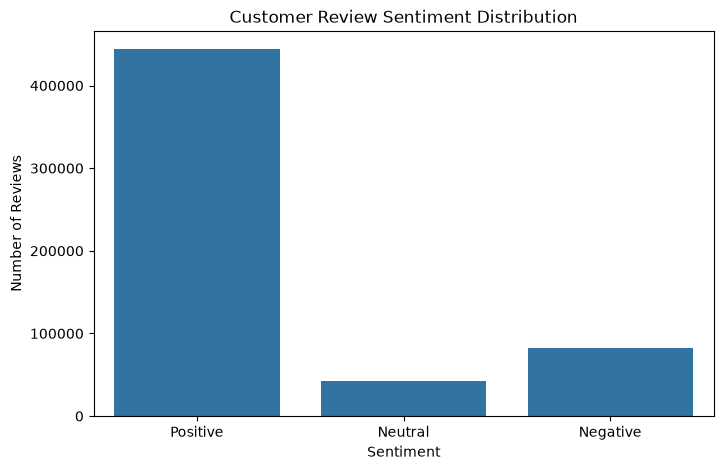

In [11]:
# Visualize the sentiment distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

## 4. NLP-Based Sentiment Analysis

The previous sentiment labels were created using customer ratings.

Now we will perform sentiment analysis directly on the review text using **VADER (Valence Aware Dictionary and sEntiment Reasoner)**.

VADER is a rule-based sentiment analysis tool designed for text. It produces a compound sentiment score that can be used to classify text as positive, neutral, or negative.

In [12]:
# Import the VADER sentiment analyzer

from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download the VADER lexicon
nltk.download("vader_lexicon")

# Create the sentiment analyzer
sia = SentimentIntensityAnalyzer()

print("VADER sentiment analyzer is ready!")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\vijay\AppData\Roaming\nltk_data...


VADER sentiment analyzer is ready!


## 4.1 Testing VADER on a Sample Review

Before applying sentiment analysis to the complete dataset, we test VADER on a single customer review.

The `compound` score ranges from -1 to +1:
- Values closer to +1 indicate positive sentiment
- Values closer to -1 indicate negative sentiment
- Values near 0 indicate neutral sentiment

In [13]:
# Select the first review
sample_review = df["Text"].iloc[0]

# Calculate sentiment scores
sample_scores = sia.polarity_scores(sample_review)

print("Review:")
print(sample_review)

print("\nVADER Scores:")
print(sample_scores)

Review:
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.

VADER Scores:
{'neg': 0.0, 'neu': 0.695, 'pos': 0.305, 'compound': 0.9441}


## 4.2 Converting VADER Scores into Sentiment Categories

VADER provides a `compound` score between -1 and +1.

We use the following thresholds:

- **Compound ≥ 0.05 → Positive**
- **Compound ≤ -0.05 → Negative**
- **Between -0.05 and 0.05 → Neutral**

These thresholds are commonly used with VADER for three-class sentiment classification.

In [14]:
# Function to convert VADER compound scores into sentiment labels

def vader_sentiment(text):
    score = sia.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


# Test the function on our sample review
print("VADER Sentiment:", vader_sentiment(sample_review))

VADER Sentiment: Positive


## 4.3 Applying VADER to the Reviews

VADER is now applied to the customer review text to calculate a sentiment score for each review.

The compound score ranges from -1 (very negative) to +1 (very positive).

In [17]:
from tqdm import tqdm

tqdm.pandas(desc="Analyzing reviews")

df["VADER_Score"] = df["Text"].progress_apply(
    lambda text: sia.polarity_scores(text)["compound"]
)

print("VADER sentiment analysis completed!")

Analyzing reviews: 100%|██████████| 568454/568454 [05:02<00:00, 1880.34it/s]

VADER sentiment analysis completed!


## 4.4 Converting VADER Scores into Sentiment Categories

The VADER compound score ranges from -1 to +1.

- Compound score ≥ 0.05 → Positive
- Compound score ≤ -0.05 → Negative
- Otherwise → Neutral

In [18]:
def vader_sentiment_from_score(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["VADER_Sentiment"] = df["VADER_Score"].apply(vader_sentiment_from_score)

print("VADER sentiment categories created!")

VADER sentiment categories created!


In [19]:
df["VADER_Sentiment"].value_counts()

VADER_Sentiment
Positive    496975
Negative     59335
Neutral      12144
Name: count, dtype: int64

## 4.5 VADER Sentiment Distribution

The distribution of sentiment categories identified by VADER is visualized to understand the overall sentiment expressed in the customer reviews.

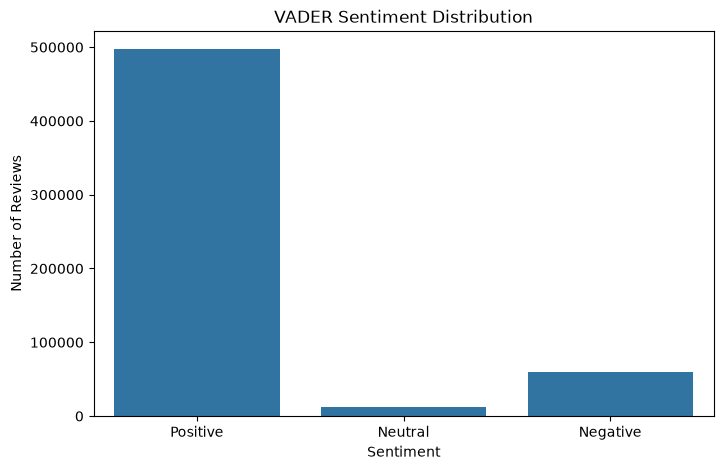

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="VADER_Sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("VADER Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

## 5. Comparing Rating-Based and VADER Sentiment

The customer rating provides a simple sentiment indication, while VADER analyzes the actual review text.

Comparing both approaches helps us understand how closely the textual sentiment matches the customer's rating.

In [21]:
comparison = pd.crosstab(
    df["Sentiment"],
    df["VADER_Sentiment"]
)

comparison

VADER_Sentiment,Negative,Neutral,Positive
Sentiment,,,
Negative,32938,4092,45007
Neutral,7628,1579,33433
Positive,18769,6473,418535


## 5.1 Sentiment Comparison Heatmap

The heatmap shows the relationship between sentiment derived from customer ratings and sentiment detected from review text using VADER.

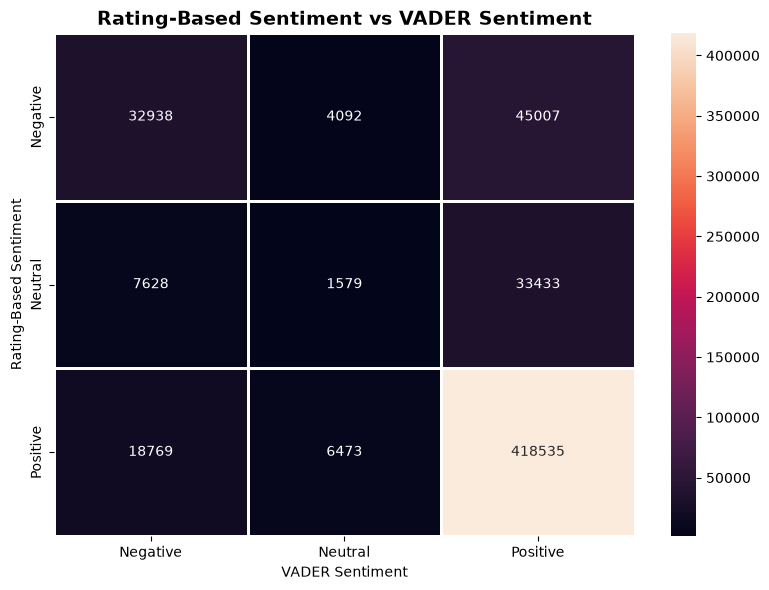

In [29]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt="d",
    cmap="rocket",
    linewidths=1,
    linecolor="white"
)

plt.title("Rating-Based Sentiment vs VADER Sentiment", fontsize=14, fontweight="bold")
plt.xlabel("VADER Sentiment")
plt.ylabel("Rating-Based Sentiment")
plt.tight_layout()
plt.show()

## 5.2 Sentiment Agreement

The percentage of reviews where rating-based sentiment and VADER sentiment are the same is calculated to measure their overall agreement.

In [30]:
agreement = (df["Sentiment"] == df["VADER_Sentiment"]).mean() * 100

print(f"Overall sentiment agreement: {agreement:.2f}%")

Overall sentiment agreement: 79.70%


## 5.3 Interpreting Sentiment Agreement

The rating-based sentiment and VADER sentiment agree for approximately 79.70% of the reviews.

The disagreement indicates that star ratings and the language used in review text do not always express sentiment in the same way. This can occur because customers may use positive or negative language while giving a rating that does not directly match the overall textual sentiment.

In [31]:
agreement_count = (df["Sentiment"] == df["VADER_Sentiment"]).sum()
disagreement_count = (df["Sentiment"] != df["VADER_Sentiment"]).sum()

print("Matching reviews:", agreement_count)
print("Different reviews:", disagreement_count)

Matching reviews: 453052
Different reviews: 115402


## 6. Analyzing Sentiment Disagreements

Some reviews receive different sentiment classifications from the customer rating and VADER.

Examining these reviews helps identify cases where the language of the review does not directly match the star rating.

In [32]:
disagreements = df[
    df["Sentiment"] != df["VADER_Sentiment"]
]

print("Number of disagreement cases:", len(disagreements))

disagreements[
    ["Score", "Sentiment", "VADER_Sentiment", "Summary", "Text"]
].head(10)

Number of disagreement cases: 115402


,Score,Sentiment,VADER_Sentiment,Summary,Text
3,2,Negative,Neutral,Cough Medicine,If you are looking for the secret ingredient i...
11,5,Positive,Negative,"My cats LOVE this ""diet"" food better than thei...",One of my boys needed to lose some weight and ...
12,1,Negative,Positive,My Cats Are Not Fans of the New Food,My cats have been happily eating Felidae Plati...
16,2,Negative,Positive,poor taste,I love eating them and they are good for watch...
25,5,Positive,Neutral,Twizzlers - Strawberry,Product received is as advertised.<br /><br />...
47,3,Neutral,Positive,Mushy,"The flavors are good. However, I do not see a..."
49,3,Neutral,Positive,Same stuff,This is the same stuff you can buy at the big ...
52,4,Positive,Negative,You'll go nuts over Ass-Kickin' Peanuts.,This wasn't in stock the last time I looked. I...
53,3,Neutral,Negative,not ass kickin,we're used to spicy foods down here in south t...
60,3,Neutral,Positive,Better price for this at Target,Watch your prices with this. While the assort...


## 6.1 Examples of Rating and Text Sentiment Disagreement

The disagreement cases show that automated text sentiment does not always correspond to the customer's overall star rating.

Positive or negative words within a review can influence VADER even when the overall customer experience, represented by the rating, suggests a different sentiment.

In [33]:
disagreement_patterns = pd.crosstab(
    disagreements["Sentiment"],
    disagreements["VADER_Sentiment"]
)

disagreement_patterns

VADER_Sentiment,Negative,Neutral,Positive
Sentiment,,,
Negative,0,4092,45007
Neutral,7628,0,33433
Positive,18769,6473,0


## 6.2 Visualization of Sentiment Disagreement Patterns

This visualization shows how rating-based sentiment and VADER sentiment differ among reviews where the two methods disagree.

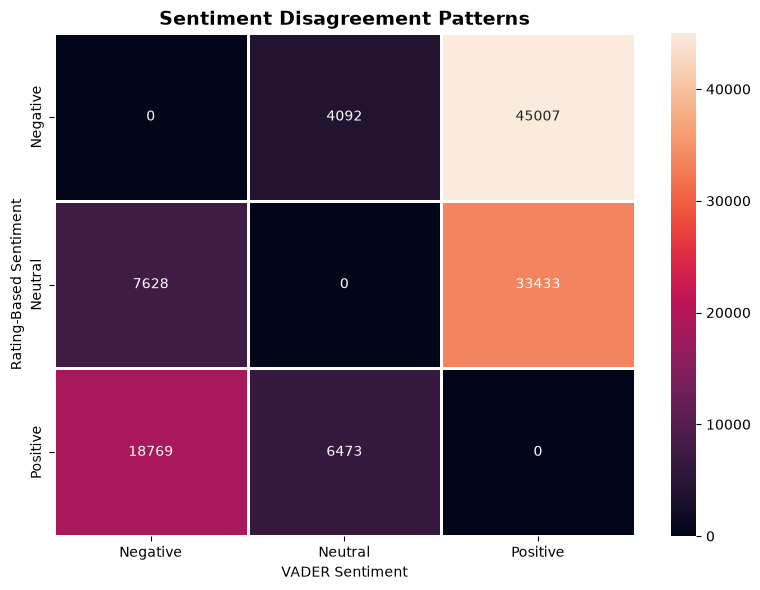

In [34]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    disagreement_patterns,
    annot=True,
    fmt="d",
    cmap="rocket",
    linewidths=1,
    linecolor="white"
)

plt.title(
    "Sentiment Disagreement Patterns",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("VADER Sentiment")
plt.ylabel("Rating-Based Sentiment")
plt.tight_layout()
plt.show()

## 6.3 Interpreting Sentiment Disagreement

The disagreement analysis shows that rating-based sentiment and text-based sentiment do not always produce the same result.

The largest disagreement occurs when reviews are classified as Negative based on their star rating but Positive by VADER. There are 45,007 such reviews.

Another notable pattern is Neutral rating-based sentiment being classified as Positive by VADER, with 33,433 cases.

These differences highlight an important limitation of sentiment analysis: customer ratings represent an overall evaluation, while VADER analyzes the emotional tone of the written text. A review may therefore contain positive words even when the customer's overall rating is low.

## 7. Final Sentiment Analysis Summary

This section summarizes the main findings from the customer review sentiment analysis.

In [35]:
# Calculate final sentiment percentages

rating_sentiment_percent = (
    df["Sentiment"].value_counts(normalize=True) * 100
).round(2)

vader_sentiment_percent = (
    df["VADER_Sentiment"].value_counts(normalize=True) * 100
).round(2)

print("Rating-Based Sentiment:")
print(rating_sentiment_percent)

print("\nVADER Sentiment:")
print(vader_sentiment_percent)

print(f"\nOverall Sentiment Agreement: {agreement:.2f}%")

Rating-Based Sentiment:
Sentiment
Positive    78.07
Negative    14.43
Neutral      7.50
Name: proportion, dtype: float64

VADER Sentiment:
VADER_Sentiment
Positive    87.43
Negative    10.44
Neutral      2.14
Name: proportion, dtype: float64

Overall Sentiment Agreement: 79.70%


## 8. Customer Voice Impact Analysis

Sentiment alone does not indicate how influential a review is. A review may be strongly negative or positive but receive little attention from other customers.

To understand the impact of customer feedback, we analyze review helpfulness along with sentiment. This helps identify sentiment categories that receive greater engagement from other customers.

In [36]:
# Calculate helpfulness ratio

df["Helpfulness_Ratio"] = (
    df["HelpfulnessNumerator"] /
    df["HelpfulnessDenominator"].replace(0, pd.NA)
)

# Display helpfulness statistics by sentiment
helpfulness_summary = (
    df.groupby("Sentiment")["Helpfulness_Ratio"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Helpfulness Ratio by Sentiment:")
print((helpfulness_summary * 100).round(2))

Average Helpfulness Ratio by Sentiment:
Sentiment
Positive     85.7
Neutral     62.55
Negative     54.8
Name: Helpfulness_Ratio, dtype: object


## 8.1 Reliable Customer Engagement Analysis

To avoid overinterpreting reviews with very few helpfulness votes, we focus on reviews that received at least 10 helpfulness votes.

This provides a more reliable view of which sentiment categories receive meaningful engagement from other customers.

In [37]:
# Keep reviews with meaningful helpfulness engagement
engaged_reviews = df[
    df["HelpfulnessDenominator"] >= 10
].copy()

engagement_summary = (
    engaged_reviews.groupby("Sentiment")["Helpfulness_Ratio"]
    .mean()
    .sort_values(ascending=False)
)

print("Number of engaged reviews:", len(engaged_reviews))
print("\nAverage Helpfulness Ratio for Engaged Reviews:")
print((engagement_summary * 100).round(2))

Number of engaged reviews: 24982

Average Helpfulness Ratio for Engaged Reviews:
Sentiment
Positive     90.5
Neutral     70.45
Negative    55.43
Name: Helpfulness_Ratio, dtype: object


## 8.2 Sentiment vs Customer Engagement

The analysis shows a clear difference in average helpfulness among reviews with at least 10 helpfulness votes.

Comparing sentiment with engagement helps identify which types of customer feedback are considered more useful by other customers.

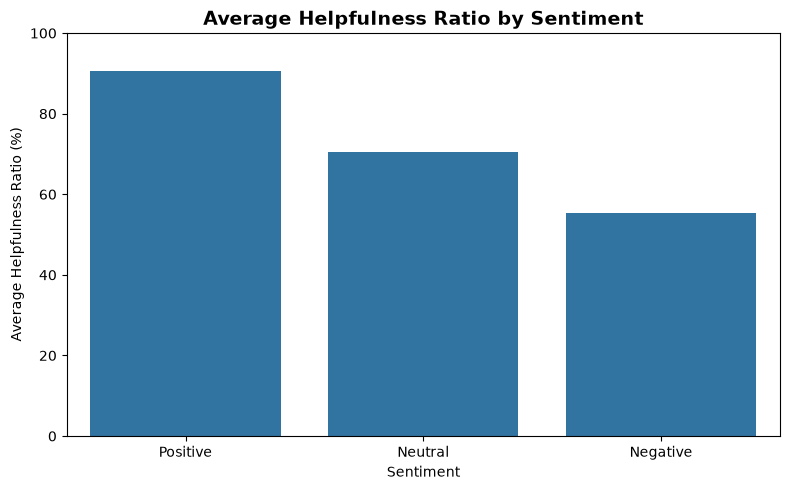

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=engagement_summary.index,
    y=engagement_summary.values * 100,
    order=["Positive", "Neutral", "Negative"]
)

plt.title(
    "Average Helpfulness Ratio by Sentiment",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Sentiment")
plt.ylabel("Average Helpfulness Ratio (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

## 8.3 Identifying Influential Customer Reviews

To understand which customer feedback receives the most attention, we identify reviews with the highest number of helpful votes.

Reviews with at least 10 total helpfulness votes are considered for this analysis. The number of helpful votes is used as an influence indicator because it represents how many customers found the review useful.

In [39]:
# Find the most influential reviews based on helpful votes

top_influential_reviews = (
    engaged_reviews
    .sort_values("HelpfulnessNumerator", ascending=False)
    [
        [
            "Score",
            "Sentiment",
            "VADER_Sentiment",
            "HelpfulnessNumerator",
            "HelpfulnessDenominator",
            "Helpfulness_Ratio",
            "Summary",
            "Text"
        ]
    ]
    .head(10)
)

top_influential_reviews

,Score,Sentiment,VADER_Sentiment,HelpfulnessNumerator,HelpfulnessDenominator,Helpfulness_Ratio,Summary,Text
190733,5,Positive,Positive,866,878,0.986333,Works as Advertised - Classy Product,see update at end of review<br /><br />*******...
207712,3,Neutral,Negative,844,923,0.91441,Whole Rabbit - NOT!,"I ordered one of these Fresh ""Whole"" Rabbits, ..."
566779,5,Positive,Negative,808,815,0.991411,sauce not for mortals,I purchased a burrito from a small shop a few ...
235722,1,Negative,Positive,580,593,0.978078,Lost in Translation: Truth,"This product is called ""Hunmatsu-RyokuCha,"" in..."
210511,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...,This Ecobrew reusable Keurig K-cup is great fo...
385450,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...,This Ecobrew reusable Keurig K-cup is great fo...
287184,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...,This Ecobrew reusable Keurig K-cup is great fo...
130478,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...,This Ecobrew reusable Keurig K-cup is great fo...
297366,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...,This Ecobrew reusable Keurig K-cup is great fo...
116802,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...,This Ecobrew reusable Keurig K-cup is great fo...


## 8.4 Detecting Duplicate Customer Reviews

Before identifying the most influential reviews, duplicate review texts should be detected.

Duplicate records can cause the same customer feedback to appear multiple times and may distort rankings based on helpfulness. Therefore, duplicate reviews are identified before performing the final influence analysis.

In [40]:
# Check for duplicate review texts
duplicate_reviews = df[df["Text"].duplicated(keep=False)].copy()

print("Total duplicate review records:", len(duplicate_reviews))
print("Unique duplicated review texts:", duplicate_reviews["Text"].nunique())

Total duplicate review records: 232915
Unique duplicated review texts: 58040


## 8.5 Creating a Unique Review Set for Influence Analysis

Duplicate review texts can appear multiple times in the dataset. Removing them from the original dataset could affect the overall sentiment analysis, so the original data is preserved.

For influence analysis, however, each unique review text should be represented only once. When the same review appears multiple times, the record with the highest number of helpful votes is retained.

This prevents repeated review text from dominating the influential-review ranking.

In [41]:
# Create a unique review set for influence analysis

unique_reviews = (
    engaged_reviews
    .sort_values("HelpfulnessNumerator", ascending=False)
    .drop_duplicates(subset="Text", keep="first")
    .copy()
)

print("Engaged reviews:", len(engaged_reviews))
print("Unique reviews used for influence analysis:", len(unique_reviews))

Engaged reviews: 24982
Unique reviews used for influence analysis: 17357


## 8.6 Top Influential Customer Voices

After removing duplicate review text from the influence analysis, the remaining unique reviews are ranked by the number of helpful votes.

These reviews represent customer feedback that received substantial attention from other customers.

In [42]:
top_unique_reviews = (
    unique_reviews
    .sort_values(
        ["HelpfulnessNumerator", "Helpfulness_Ratio"],
        ascending=[False, False]
    )
    [
        [
            "Score",
            "Sentiment",
            "VADER_Sentiment",
            "HelpfulnessNumerator",
            "HelpfulnessDenominator",
            "Helpfulness_Ratio",
            "Summary"
        ]
    ]
    .head(10)
)

top_unique_reviews

,Score,Sentiment,VADER_Sentiment,HelpfulnessNumerator,HelpfulnessDenominator,Helpfulness_Ratio,Summary
190733,5,Positive,Positive,866,878,0.986333,Works as Advertised - Classy Product
207712,3,Neutral,Negative,844,923,0.91441,Whole Rabbit - NOT!
566779,5,Positive,Negative,808,815,0.991411,sauce not for mortals
235722,1,Negative,Positive,580,593,0.978078,Lost in Translation: Truth
210511,5,Positive,Positive,559,562,0.994662,Works great! But how does it compare to Solofi...
375916,5,Positive,Positive,538,544,0.988971,Money saver!!
88407,5,Positive,Positive,536,539,0.994434,"Good sampler, but what's included?"
190734,2,Negative,Positive,524,536,0.977612,A Nice Item That Makes a Horrible Racket
222937,3,Neutral,Positive,491,569,0.862917,"not bad stuff, but I have serious questions"
373776,5,Positive,Positive,488,496,0.983871,A Slacker Mom's dream


## 8.7 Influential Sentiment Conflicts

Some customer reviews receive substantial attention even when their star rating and text-based sentiment disagree.

These reviews are particularly interesting because they may contain nuanced opinions, mixed experiences, sarcasm, or contextual language that a simple sentiment classifier cannot fully capture.

We therefore identify highly helpful reviews where rating-based sentiment and VADER sentiment disagree.

In [43]:
# Find unique reviews where rating-based and VADER sentiment disagree

conflict_reviews = unique_reviews[
    unique_reviews["Sentiment"] != unique_reviews["VADER_Sentiment"]
].copy()

# Rank conflicts by number of helpful votes
top_conflict_reviews = (
    conflict_reviews
    .sort_values(
        ["HelpfulnessNumerator", "Helpfulness_Ratio"],
        ascending=[False, False]
    )
    [
        [
            "Score",
            "Sentiment",
            "VADER_Sentiment",
            "HelpfulnessNumerator",
            "HelpfulnessDenominator",
            "Helpfulness_Ratio",
            "Summary"
        ]
    ]
    .head(10)
)

top_conflict_reviews

,Score,Sentiment,VADER_Sentiment,HelpfulnessNumerator,HelpfulnessDenominator,Helpfulness_Ratio,Summary
207712,3,Neutral,Negative,844,923,0.91441,Whole Rabbit - NOT!
566779,5,Positive,Negative,808,815,0.991411,sauce not for mortals
235722,1,Negative,Positive,580,593,0.978078,Lost in Translation: Truth
190734,2,Negative,Positive,524,536,0.977612,A Nice Item That Makes a Horrible Racket
222937,3,Neutral,Positive,491,569,0.862917,"not bad stuff, but I have serious questions"
268064,5,Positive,Neutral,466,488,0.954918,Serious Problem
268059,5,Positive,Negative,439,452,0.971239,What Do You Mean I Can't Bring My Milk???
268058,5,Positive,Negative,356,365,0.975342,Habitat of the Tuscan Whole
226505,2,Negative,Positive,355,360,0.986111,"Great Idea, BAD Marketing"
279312,1,Negative,Positive,354,383,0.924282,Not Satisfied!


## 8.8 Influential Sentiment Conflict Patterns

The most helpful sentiment-conflicting reviews are grouped by their rating-based and VADER sentiment combinations.

This helps identify which types of sentiment conflicts receive the greatest attention from other customers.

In [44]:
# Create sentiment conflict categories

conflict_patterns = (
    conflict_reviews
    .groupby(["Sentiment", "VADER_Sentiment"])["HelpfulnessNumerator"]
    .sum()
    .reset_index()
)

conflict_patterns["Conflict_Type"] = (
    conflict_patterns["Sentiment"]
    + " → "
    + conflict_patterns["VADER_Sentiment"]
)

conflict_patterns = conflict_patterns.sort_values(
    "HelpfulnessNumerator",
    ascending=False
)

conflict_patterns

,Sentiment,VADER_Sentiment,HelpfulnessNumerator,Conflict_Type
1,Negative,Positive,46386,Negative → Positive
3,Neutral,Positive,18948,Neutral → Positive
4,Positive,Negative,13666,Positive → Negative
2,Neutral,Negative,4344,Neutral → Negative
0,Negative,Neutral,3155,Negative → Neutral
5,Positive,Neutral,2770,Positive → Neutral


## 8.9 Customer Attention to Sentiment Conflicts

The total number of helpful votes is used as an indicator of customer attention toward sentiment-conflicting reviews.

The analysis shows that Negative → Positive conflicts received the highest total number of helpful votes, followed by Neutral → Positive conflicts.

This suggests that reviews where the customer's overall rating differs from the emotional tone of the written text can attract substantial attention from other customers.

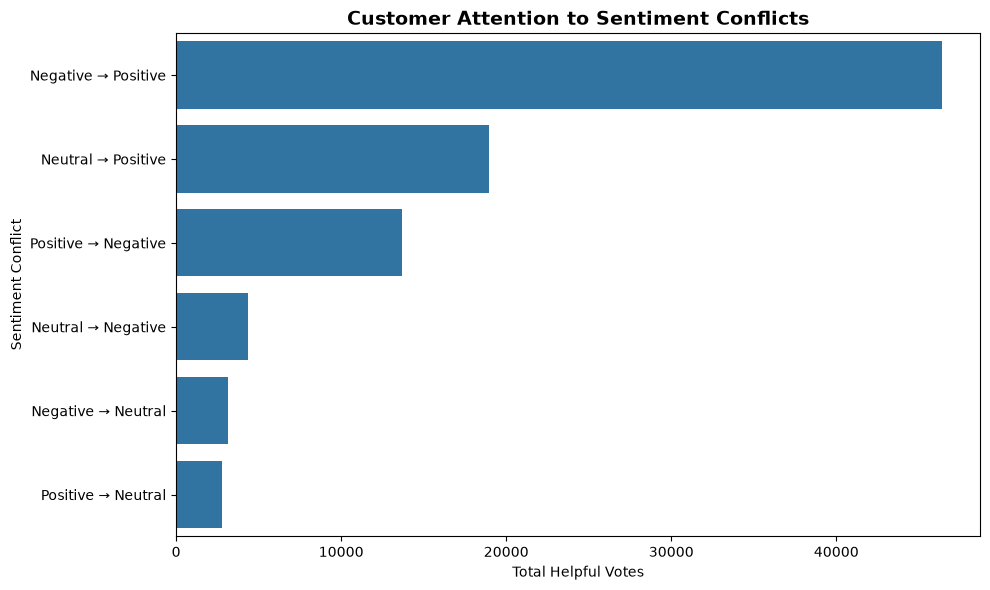

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=conflict_patterns,
    x="HelpfulnessNumerator",
    y="Conflict_Type"
)

plt.title(
    "Customer Attention to Sentiment Conflicts",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Helpful Votes")
plt.ylabel("Sentiment Conflict")

plt.tight_layout()
plt.show()

## 8.10 Interpretation of Customer Attention

The conflict analysis reveals that the largest share of helpful votes belongs to Negative → Positive conflicts, with 46,386 helpful votes.

This indicates that reviews with a low rating but positive textual language can receive substantial customer attention. Other notable patterns include Neutral → Positive and Positive → Negative conflicts.

These results suggest that sentiment disagreement can reveal reviews containing nuanced or mixed customer experiences that may be missed when relying on star ratings alone.

Helpful votes are treated as a proxy for customer attention rather than a direct measure of review quality or influence.

## 9. Customer Feedback Themes

Sentiment classification tells us whether customer feedback is positive, neutral, or negative, but it does not explain what customers are talking about.

In this section, frequently occurring meaningful words are analyzed separately for positive and negative reviews to identify common customer feedback themes.

In [46]:
from collections import Counter
import re

# Sample reviews for theme analysis
positive_reviews = df[df["Sentiment"] == "Positive"]["Text"].sample(
    n=10000, random_state=42
)

negative_reviews = df[df["Sentiment"] == "Negative"]["Text"].sample(
    n=10000, random_state=42
)

print("Positive reviews sampled:", len(positive_reviews))
print("Negative reviews sampled:", len(negative_reviews))

Positive reviews sampled: 10000
Negative reviews sampled: 10000


In [47]:
# Common English words to remove
stop_words = {
    "the", "and", "a", "an", "to", "of", "in", "is", "it", "for",
    "on", "that", "this", "with", "was", "as", "are", "be", "but",
    "have", "has", "had", "i", "we", "you", "they", "my", "our",
    "their", "me", "he", "she", "or", "so", "if", "from", "at",
    "by", "not", "very", "just", "can", "would", "will", "do",
    "did", "been", "were", "its", "it's", "im", "don't", "didn't"
}

def extract_words(text):
    words = re.findall(r"\b[a-zA-Z]{3,}\b", text.lower())
    return [word for word in words if word not in stop_words]

positive_words = []
negative_words = []

for review in positive_reviews:
    positive_words.extend(extract_words(review))

for review in negative_reviews:
    negative_words.extend(extract_words(review))

positive_word_counts = Counter(positive_words)
negative_word_counts = Counter(negative_words)

print("Positive words extracted:", len(positive_words))
print("Negative words extracted:", len(negative_words))

Positive words extracted: 434571
Negative words extracted: 504442


In [48]:
# Get the 20 most common words for each sentiment

top_positive_words = positive_word_counts.most_common(20)
top_negative_words = negative_word_counts.most_common(20)

print("Top 20 Words in Positive Reviews:")
for word, count in top_positive_words:
    print(f"{word}: {count}")

print("\nTop 20 Words in Negative Reviews:")
for word, count in top_negative_words:
    print(f"{word}: {count}")

Top 20 Words in Positive Reviews:
these: 4092
like: 4072
them: 3750
good: 3622
great: 3374
coffee: 3020
one: 2878
taste: 2848
all: 2766
product: 2616
flavor: 2511
love: 2488
tea: 2459
when: 2379
more: 2316
food: 2195
than: 2016
out: 1875
other: 1843
amazon: 1843

Top 20 Words in Negative Reviews:
like: 5556
product: 4311
taste: 4019
these: 3793
them: 3611
one: 3448
all: 3423
food: 2896
out: 2756
coffee: 2754
good: 2658
when: 2652
flavor: 2560
what: 2434
more: 2381
there: 2166
even: 2131
tea: 2129
amazon: 2085
about: 2071


In [49]:
# Expand stop words to remove common non-informative words

stop_words.update({
    "these", "those", "them", "there", "here", "one", "two",
    "also", "more", "most", "much", "many", "some", "any",
    "all", "when", "where", "what", "which", "who", "how",
    "than", "then", "out", "other", "into", "over", "after",
    "before", "because", "about", "only", "still", "really",
    "quite", "well", "got", "get", "getting", "make", "made",
    "making", "use", "used", "using", "want", "wanted"
})

# Recalculate meaningful words
positive_words = []
negative_words = []

for review in positive_reviews:
    positive_words.extend(extract_words(review))

for review in negative_reviews:
    negative_words.extend(extract_words(review))

positive_word_counts = Counter(positive_words)
negative_word_counts = Counter(negative_words)

print("Updated positive words:", len(positive_words))
print("Updated negative words:", len(negative_words))

Updated positive words: 373235
Updated negative words: 434454


In [50]:
top_positive_words = positive_word_counts.most_common(20)
top_negative_words = negative_word_counts.most_common(20)

print("Top 20 Meaningful Words in Positive Reviews:")
print(top_positive_words)

print("\nTop 20 Meaningful Words in Negative Reviews:")
print(top_negative_words)

Top 20 Meaningful Words in Positive Reviews:
[('like', 4072), ('good', 3622), ('great', 3374), ('coffee', 3020), ('taste', 2848), ('product', 2616), ('flavor', 2511), ('love', 2488), ('tea', 2459), ('food', 2195), ('amazon', 1843), ('too', 1695), ('little', 1574), ('best', 1505), ('your', 1473), ('don', 1457), ('time', 1419), ('price', 1379), ('find', 1324), ('tried', 1295)]

Top 20 Meaningful Words in Negative Reviews:
[('like', 5556), ('product', 4311), ('taste', 4019), ('food', 2896), ('coffee', 2754), ('good', 2658), ('flavor', 2560), ('even', 2131), ('tea', 2129), ('amazon', 2085), ('don', 2008), ('buy', 1859), ('your', 1816), ('dog', 1624), ('again', 1606), ('tried', 1536), ('first', 1465), ('too', 1449), ('time', 1441), ('now', 1425)]


## 9.1 Distinctive Customer Feedback Words

Raw word frequency can be misleading because common words may appear frequently in both positive and negative reviews.

To identify more meaningful customer themes, we compare the frequency of words between positive and negative reviews. Words that occur disproportionately more often in one sentiment group can provide stronger clues about customer experiences.

In [51]:
# Calculate word frequencies per review group

positive_total = len(positive_words)
negative_total = len(negative_words)

distinctive_words = []

all_words = set(positive_word_counts) | set(negative_word_counts)

for word in all_words:
    positive_rate = positive_word_counts[word] / positive_total
    negative_rate = negative_word_counts[word] / negative_total
    
    # Difference in normalized frequency
    difference = positive_rate - negative_rate
    
    distinctive_words.append(
        (word, positive_rate, negative_rate, difference)
    )

distinctive_words_df = pd.DataFrame(
    distinctive_words,
    columns=[
        "Word",
        "Positive_Rate",
        "Negative_Rate",
        "Difference"
    ]
)

print("Distinctive words identified:", len(distinctive_words_df))

Distinctive words identified: 26379


In [53]:
# Words that are relatively more common in positive reviews
top_positive_distinctive = (
    distinctive_words_df
    .sort_values("Difference", ascending=False)
    .head(15)
)

# Words that are relatively more common in negative reviews
top_negative_distinctive = (
    distinctive_words_df
    .sort_values("Difference", ascending=True)
    .head(15)
)

print("Words distinctive to Positive Reviews:")
print(
    top_positive_distinctive[
        ["Word", "Positive_Rate", "Negative_Rate", "Difference"]
    ].to_string(index=False)
)

print("\nWords distinctive to Negative Reviews:")
print(
    top_negative_distinctive[
        ["Word", "Positive_Rate", "Negative_Rate", "Difference"]
    ].to_string(index=False)
)

Words distinctive to Positive Reviews:
     Word  Positive_Rate  Negative_Rate  Difference
    great       0.009040       0.002562    0.006478
     love       0.006666       0.002392    0.004275
     good       0.009704       0.006118    0.003586
     best       0.004032       0.001356    0.002677
delicious       0.002315       0.000428    0.001887
   coffee       0.008091       0.006339    0.001752
      tea       0.006588       0.004900    0.001688
  perfect       0.001843       0.000244    0.001599
     nice       0.002280       0.000695    0.001585
 favorite       0.002312       0.000732    0.001580
    loves       0.002026       0.000499    0.001526
   little       0.004217       0.002693    0.001524
     find       0.003547       0.002157    0.001391
    snack       0.001881       0.000504    0.001377
     easy       0.001637       0.000407    0.001230

Words distinctive to Negative Reviews:
        Word  Positive_Rate  Negative_Rate  Difference
     product       0.007009       

## 9.2 Positive vs Negative Customer Language

The distinctive-word analysis highlights vocabulary that is relatively more common in positive or negative reviews.

Instead of relying only on raw word counts, the analysis compares normalized word frequencies between the two sentiment groups. This helps identify language that is more strongly associated with different customer experiences.

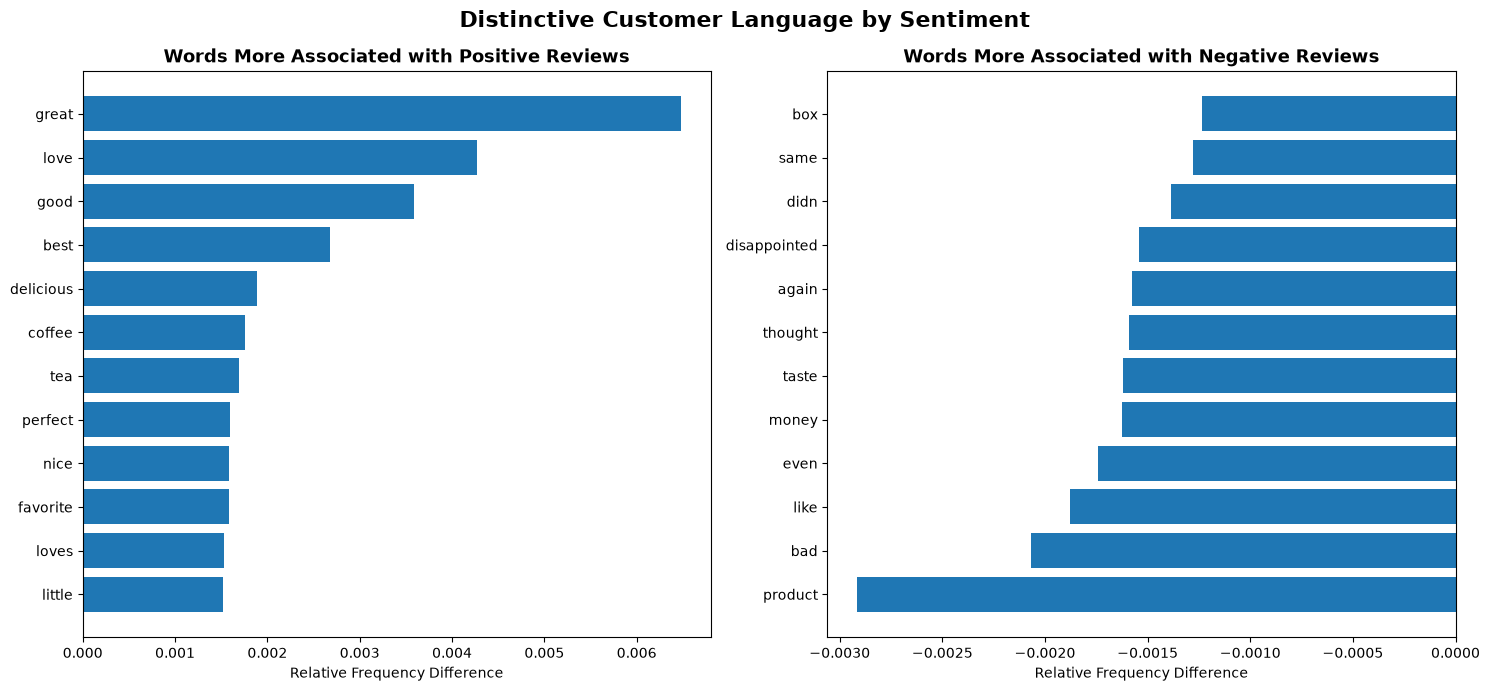

In [54]:
# Select the most distinctive words for each sentiment

top_positive = (
    distinctive_words_df
    .sort_values("Difference", ascending=False)
    .head(12)
    .sort_values("Difference")
)

top_negative = (
    distinctive_words_df
    .sort_values("Difference", ascending=True)
    .head(12)
    .sort_values("Difference")
)

# Create side-by-side visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Positive words
axes[0].barh(
    top_positive["Word"],
    top_positive["Difference"]
)

axes[0].set_title(
    "Words More Associated with Positive Reviews",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Relative Frequency Difference")
axes[0].set_ylabel("")

# Negative words
axes[1].barh(
    top_negative["Word"],
    top_negative["Difference"]
)

axes[1].set_title(
    "Words More Associated with Negative Reviews",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Relative Frequency Difference")
axes[1].set_ylabel("")

plt.suptitle(
    "Distinctive Customer Language by Sentiment",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 9.3 Customer Feedback Themes

Distinctive words provide useful signals, but individual words do not always represent complete customer concerns.

To make the analysis more actionable, selected words are grouped into broader customer feedback themes such as taste, product quality, price/value, and convenience.

These themes help translate sentiment results into practical customer insights.

In [55]:
# Define practical customer feedback themes

theme_keywords = {
    "Taste & Flavor": [
        "taste", "flavor", "delicious", "coffee", "tea", "snack"
    ],
    
    "Product Quality": [
        "product", "quality", "good", "great", "best", "perfect"
    ],
    
    "Price & Value": [
        "price", "money", "cost", "value", "expensive", "cheap"
    ],
    
    "Purchase Experience": [
        "bought", "buy", "amazon", "order", "ordered", "delivery"
    ],
    
    "Pet & Food Experience": [
        "food", "dog", "cat", "cats", "pet", "pets"
    ],
    
    "Convenience": [
        "easy", "quick", "box", "packaging", "package"
    ]
}

print("Customer feedback themes created:")
for theme, keywords in theme_keywords.items():
    print(f"- {theme}: {', '.join(keywords)}")

Customer feedback themes created:
- Taste & Flavor: taste, flavor, delicious, coffee, tea, snack
- Product Quality: product, quality, good, great, best, perfect
- Price & Value: price, money, cost, value, expensive, cheap
- Purchase Experience: bought, buy, amazon, order, ordered, delivery
- Pet & Food Experience: food, dog, cat, cats, pet, pets
- Convenience: easy, quick, box, packaging, package


## 9.4 Measuring Customer Feedback Themes

Each review is checked for the presence of keywords associated with the defined customer feedback themes.

The analysis compares theme occurrence across positive and negative reviews to identify which areas are more prominent in different customer experiences.

In [56]:
# Measure theme occurrence in positive and negative reviews

theme_results = []

for theme, keywords in theme_keywords.items():
    positive_count = positive_reviews.str.lower().apply(
        lambda text: any(keyword in text for keyword in keywords)
    ).sum()
    
    negative_count = negative_reviews.str.lower().apply(
        lambda text: any(keyword in text for keyword in keywords)
    ).sum()
    
    theme_results.append({
        "Theme": theme,
        "Positive_Reviews": positive_count,
        "Negative_Reviews": negative_count
    })

theme_results_df = pd.DataFrame(theme_results)

print(theme_results_df.to_string(index=False))

                Theme  Positive_Reviews  Negative_Reviews
       Taste & Flavor              6238              5797
      Product Quality              6888              5402
        Price & Value              2314              2544
  Purchase Experience              3829              4811
Pet & Food Experience              2281              2437
          Convenience              2109              2407


## 9.5 Customer Feedback Theme Comparison

The theme analysis provides a more actionable view of customer sentiment.

By comparing the occurrence of each theme in positive and negative reviews, we can identify areas that are commonly associated with positive experiences as well as areas that may require closer attention.

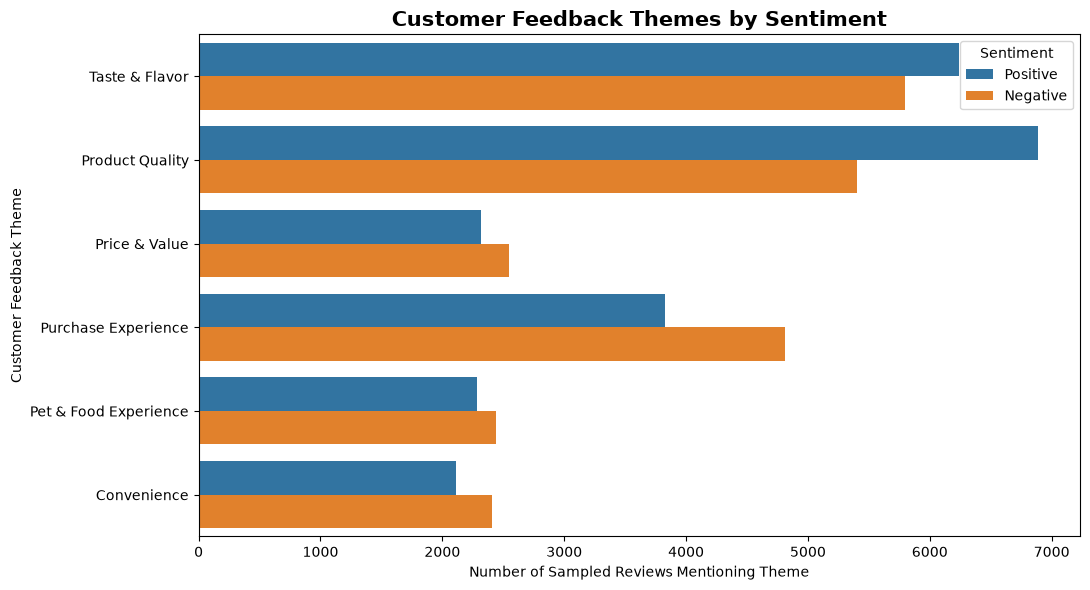

In [57]:
# Visualize positive vs negative review themes

theme_plot_df = theme_results_df.melt(
    id_vars="Theme",
    value_vars=["Positive_Reviews", "Negative_Reviews"],
    var_name="Sentiment",
    value_name="Review_Count"
)

theme_plot_df["Sentiment"] = theme_plot_df["Sentiment"].replace({
    "Positive_Reviews": "Positive",
    "Negative_Reviews": "Negative"
})

plt.figure(figsize=(11, 6))

sns.barplot(
    data=theme_plot_df,
    x="Review_Count",
    y="Theme",
    hue="Sentiment"
)

plt.title(
    "Customer Feedback Themes by Sentiment",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Sampled Reviews Mentioning Theme")
plt.ylabel("Customer Feedback Theme")

plt.tight_layout()
plt.show()

## 9.6 Theme Sentiment Gap

Review counts alone can be misleading because the positive and negative samples may contain different numbers of mentions.

To make the comparison more meaningful, the sentiment share of each theme is calculated within the sampled reviews.

The resulting sentiment gap indicates whether a theme is relatively more associated with positive or negative customer experiences.

In [58]:
# Calculate the percentage of each theme within positive and negative samples

theme_gap_df = theme_results_df.copy()

positive_sample_size = len(positive_reviews)
negative_sample_size = len(negative_reviews)

theme_gap_df["Positive_Percentage"] = (
    theme_gap_df["Positive_Reviews"] / positive_sample_size * 100
)

theme_gap_df["Negative_Percentage"] = (
    theme_gap_df["Negative_Reviews"] / negative_sample_size * 100
)

theme_gap_df["Sentiment_Gap"] = (
    theme_gap_df["Positive_Percentage"]
    - theme_gap_df["Negative_Percentage"]
)

theme_gap_df = theme_gap_df.sort_values(
    "Sentiment_Gap",
    ascending=False
)

print(
    theme_gap_df[
        [
            "Theme",
            "Positive_Percentage",
            "Negative_Percentage",
            "Sentiment_Gap"
        ]
    ].round(2).to_string(index=False)
)

                Theme  Positive_Percentage  Negative_Percentage  Sentiment_Gap
      Product Quality                68.88                54.02          14.86
       Taste & Flavor                62.38                57.97           4.41
Pet & Food Experience                22.81                24.37          -1.56
        Price & Value                23.14                25.44          -2.30
          Convenience                21.09                24.07          -2.98
  Purchase Experience                38.29                48.11          -9.82


## 9.7 Theme Sentiment Gap Visualization

The sentiment gap summarizes the relative difference between positive and negative review mentions for each customer feedback theme.

A positive gap indicates that the theme appears relatively more often in positive reviews, while a negative gap indicates that it appears relatively more often in negative reviews.

This provides a compact view of which customer experience areas are more closely associated with each sentiment group.

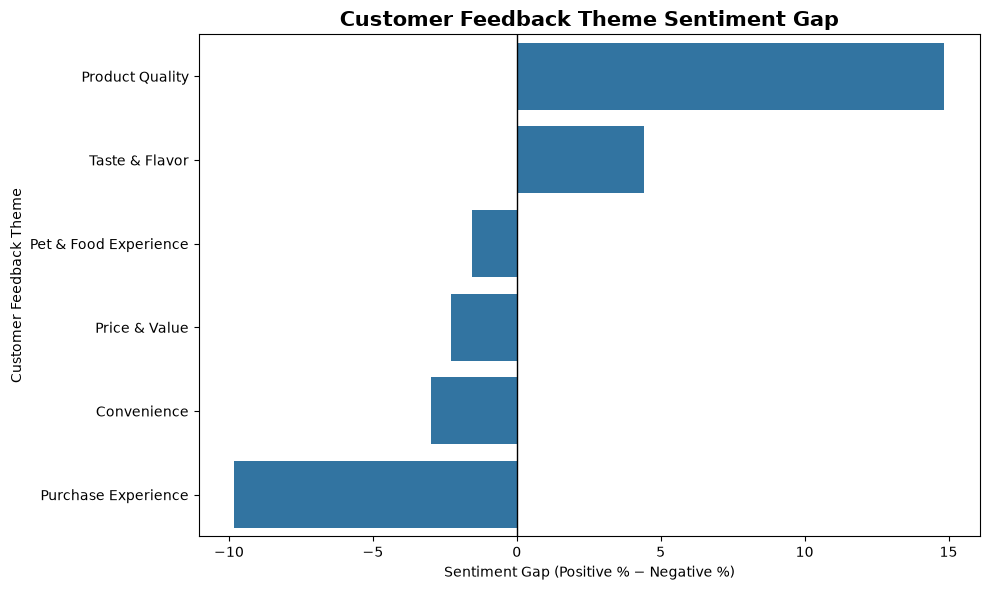

In [59]:
# Visualize the sentiment gap for each customer feedback theme

plt.figure(figsize=(10, 6))

sns.barplot(
    data=theme_gap_df,
    x="Sentiment_Gap",
    y="Theme"
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Customer Feedback Theme Sentiment Gap",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Sentiment Gap (Positive % − Negative %)")
plt.ylabel("Customer Feedback Theme")

plt.tight_layout()
plt.show()

## 9.8 Business Insights from Customer Feedback Themes

The theme sentiment gap provides several actionable observations:

- **Product Quality** has the strongest positive sentiment gap (+14.86 percentage points), indicating that quality-related language appears substantially more often in positive reviews.
- **Purchase Experience** has the strongest negative sentiment gap (−9.82 percentage points), suggesting that ordering, buying, delivery, or related experiences are relatively more prominent in negative reviews.
- **Taste & Flavor** shows a moderate positive gap (+4.41 percentage points), indicating that taste-related feedback is somewhat more associated with positive experiences.
- **Convenience** (−2.98 points) and **Price & Value** (−2.30 points) show smaller negative gaps and may represent areas worth monitoring.
- **Pet & Food Experience** has only a small negative gap (−1.56 points), suggesting a relatively balanced relationship between the two sentiment groups.

These observations are based on keyword occurrence within sampled reviews and should be interpreted as associations rather than causal relationships.

## 10. Review Length and Customer Sentiment

Review length can provide additional context about customer feedback.

Longer reviews may contain more detailed experiences, explanations, or complaints, while shorter reviews may represent quick reactions.

In this section, review length is compared across sentiment groups to identify differences in how customers express their experiences.

In [60]:
# Calculate the number of words in each review

df["Review_Length"] = df["Text"].str.split().str.len()

# Summary statistics by sentiment

review_length_summary = (
    df.groupby("Sentiment")["Review_Length"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(["Positive", "Neutral", "Negative"])
)

print(review_length_summary.round(2))

Exception ignored while calling deallocator <function tqdm.__del__ at 0x00000272E5758CA0>:
Traceback (most recent call last):
  File "c:\Users\vijay\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\std.py", line 1154, in __del__
    self.close()
  File "c:\Users\vijay\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


            count   mean  median  min   max
Sentiment                                  
Positive   443777  77.30    54.0    3  2520
Neutral     42640  95.65    70.0    7  3432
Negative    82037  88.31    64.0    3  2149


## 10.1 Review Length Distribution by Sentiment

The summary shows differences in review length across sentiment groups.

Positive reviews have the shortest average and median length, while neutral reviews have the highest values. Negative reviews are also longer than positive reviews on both measures.

Because review length distributions can contain extreme values, the median is particularly useful for understanding the typical review length.

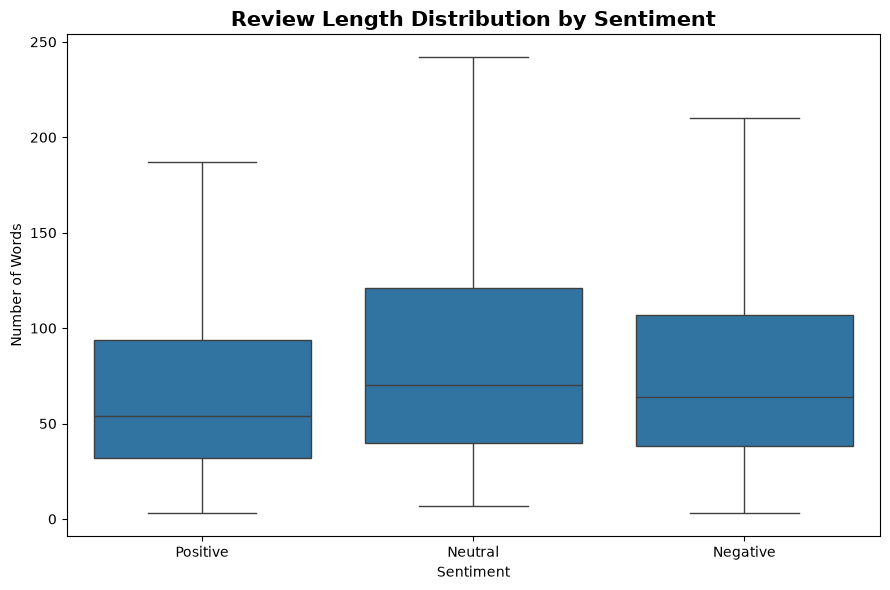

In [61]:
# Visualize the typical review length by sentiment

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Sentiment",
    y="Review_Length",
    order=["Positive", "Neutral", "Negative"],
    showfliers=False
)

plt.title(
    "Review Length Distribution by Sentiment",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

## 10.2 Review Length vs Customer Helpfulness

Review length may be related to how useful other customers find a review.

To explore this relationship, review length is compared with the number of helpful votes received. This analysis does not imply that longer reviews are inherently better; it only examines whether a relationship exists in the dataset.

In [62]:
# Analyze the relationship between review length and helpful votes

length_helpfulness = df[
    (df["HelpfulnessDenominator"] > 0) &
    (df["Review_Length"] > 0)
].copy()

correlation = length_helpfulness[
    ["Review_Length", "HelpfulnessNumerator"]
].corr().iloc[0, 1]

print(
    f"Correlation between review length and helpful votes: "
    f"{correlation:.3f}"
)

Correlation between review length and helpful votes: 0.175


## 10.3 Review Length vs Helpfulness

The correlation analysis indicates a weak positive relationship between review length and helpful votes.

To visualize this relationship clearly, a sample of reviews is used rather than plotting every observation. This reduces overplotting while preserving the overall pattern in the dataset.

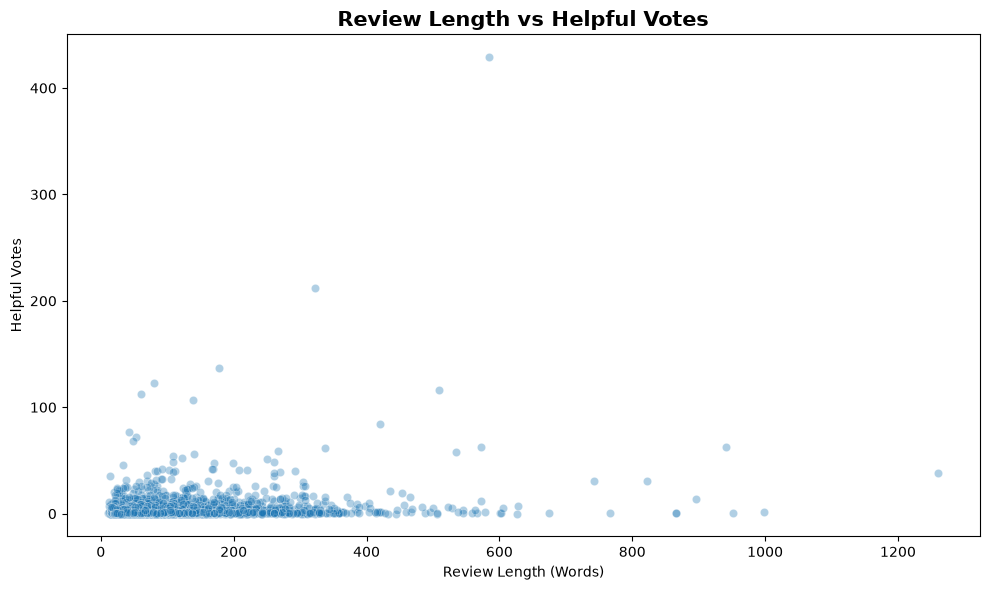

In [63]:
# Sample reviews for clearer visualization

plot_sample = length_helpfulness.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="Review_Length",
    y="HelpfulnessNumerator",
    alpha=0.35,
    s=35
)

plt.title(
    "Review Length vs Helpful Votes",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Review Length (Words)")
plt.ylabel("Helpful Votes")

plt.tight_layout()
plt.show()

## 10.4 Review Length Insights

The analysis shows that review length differs across sentiment groups.

Neutral reviews have the highest average and median length, while positive reviews tend to be shorter. The correlation between review length and helpful votes is positive but weak (0.175).

This suggests that longer reviews may receive somewhat more helpful votes, but review length alone is not a strong indicator of customer usefulness or engagement.

Overall, review length should be considered alongside sentiment, content, and customer engagement rather than treated as an independent measure of review quality.

## 11. Final Business Insights Dashboard

The analysis so far has examined customer sentiment, rating-text disagreements, customer engagement, influential reviews, feedback themes, and review length.

This section brings the most important findings together into a compact business-oriented summary.

The goal is to translate the NLP analysis into insights that could help a product or customer-experience team understand:
- Overall customer sentiment
- Major areas of positive and negative feedback
- Customer engagement with reviews
- Important sentiment conflicts
- Patterns that may require further investigation

In [ ]:
### 11.1 Key Business Metrics

The following metrics summarize the main findings from the sentiment and customer feedback analysis.

In [64]:
# Calculate key project metrics

total_reviews = len(df)

positive_pct = (df["Sentiment"] == "Positive").mean() * 100
neutral_pct = (df["Sentiment"] == "Neutral").mean() * 100
negative_pct = (df["Sentiment"] == "Negative").mean() * 100

sentiment_agreement = (
    df["Sentiment"] == df["VADER_Sentiment"]
).mean() * 100

average_review_length = df["Review_Length"].mean()

average_helpfulness = (
    df.loc[df["HelpfulnessDenominator"] > 0, "Helpfulness_Ratio"]
    .mean() * 100
)

print("CUSTOMER REVIEW INSIGHTS")
print("=" * 40)
print(f"Total Reviews              : {total_reviews:,}")
print(f"Positive Sentiment         : {positive_pct:.2f}%")
print(f"Neutral Sentiment          : {neutral_pct:.2f}%")
print(f"Negative Sentiment         : {negative_pct:.2f}%")
print(f"Rating-VADER Agreement     : {sentiment_agreement:.2f}%")
print(f"Average Review Length      : {average_review_length:.2f} words")
print(f"Average Helpfulness Ratio  : {average_helpfulness:.2f}%")

CUSTOMER REVIEW INSIGHTS
Total Reviews              : 568,454
Positive Sentiment         : 78.07%
Neutral Sentiment          : 7.50%
Negative Sentiment         : 14.43%
Rating-VADER Agreement     : 79.70%
Average Review Length      : 80.26 words
Average Helpfulness Ratio  : 77.70%


### 11.2 Business Metrics Visualization

The key metrics are visualized below to provide a quick overview of customer sentiment and review engagement.

This visualization is intended as an executive-style summary that can be quickly understood without reading the complete analysis.

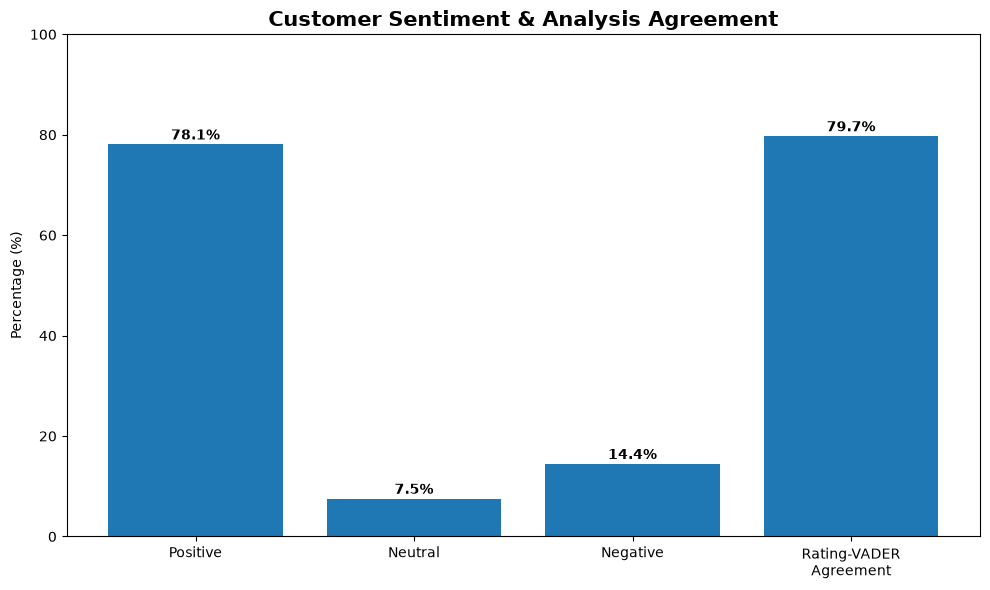

In [65]:
# Prepare key metrics for visualization

metrics = {
    "Positive": positive_pct,
    "Neutral": neutral_pct,
    "Negative": negative_pct,
    "Rating-VADER\nAgreement": sentiment_agreement
}

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.title(
    "Customer Sentiment & Analysis Agreement",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Percentage (%)")
plt.ylim(0, 100)

# Add values above bars
for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 11.3 Actionable Business Insights

The analysis provides several practical insights from customer feedback:

**1. Strong overall positive sentiment**  
Approximately 78% of reviews are classified as positive using rating-based sentiment labels, indicating that positive customer experiences dominate the dataset.

**2. Negative feedback represents an important minority**  
Around 14% of reviews are classified as negative. Although smaller than the positive segment, this group can reveal specific customer pain points.

**3. Purchase experience requires attention**  
Purchase-related terms show a negative sentiment gap of approximately 9.82 percentage points, suggesting that ordering, buying, and delivery experiences appear relatively more often in negative reviews.

**4. Product quality is strongly associated with positive feedback**  
Product-quality terms show the largest positive sentiment gap (+14.86 percentage points) among the analyzed themes.

**5. Some reviews contain sentiment ambiguity**  
The 79.70% agreement between rating-based sentiment and VADER indicates that the two approaches frequently agree, but a substantial number of reviews show disagreement. These reviews can contain mixed, contextual, or nuanced customer experiences.

**6. Customer engagement can highlight important feedback**  
Highly helpful reviews can reveal customer experiences that received considerable attention from other reviewers. Helpfulness votes should be treated as an engagement signal rather than a direct measure of review quality.

**7. Review length alone is not a strong indicator of usefulness**  
The correlation between review length and helpful votes is weak (0.175), suggesting that factors beyond length contribute to whether customers find a review useful.

Overall, combining sentiment, customer engagement, review language, themes, and disagreement analysis provides a more complete picture of customer feedback than sentiment classification alone.

## 13. Limitations & Future Improvements

### Limitations

- Rating-based sentiment labels assume that ratings of 4–5 are positive, 3 is neutral, and 1–2 are negative. This is a useful proxy but is not equivalent to human-annotated sentiment.
- VADER is a general-purpose sentiment model and may not fully understand product-specific language, sarcasm, context, or domain-specific expressions.
- The 79.70% agreement between the two approaches measures consistency between methods, not classification accuracy.
- The feedback theme analysis is keyword-based, so a review may be associated with a theme even when the context is different.
- Helpfulness votes represent customer engagement and should not be interpreted as a direct measure of review quality.
- Duplicate reviews were retained in the main dataset and removed only for the specific influence analysis where repeated text could distort the results.

### Future Improvements

The project could be extended by:

- Training a supervised machine-learning sentiment classifier using labeled reviews.
- Using TF-IDF with Logistic Regression or other classification algorithms.
- Applying transformer-based models such as BERT for context-aware sentiment analysis.
- Using topic modeling to automatically discover customer concerns instead of relying only on predefined keywords.
- Building an interactive Streamlit dashboard for business users.
- Adding product-level and category-level sentiment analysis.
- Performing time-based sentiment analysis to identify changes in customer experience.

# Amazon Customer Review Sentiment Analysis

In [2]:
import pandas as pd

df = pd.read_csv("../data/Reviews.csv")

df.shape

(568454, 10)

In [3]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [5]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon")

sia = SentimentIntensityAnalyzer()

print("VADER is ready ✅")

VADER is ready ✅


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\vijay\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [6]:
from tqdm.auto import tqdm

tqdm.pandas()

df["VADER_Compound"] = df["Text"].progress_apply(
    lambda text: sia.polarity_scores(str(text))["compound"]
)

df["VADER_Sentiment"] = df["VADER_Compound"].apply(
    lambda score: (
        "Positive" if score >= 0.05
        else "Negative" if score <= -0.05
        else "Neutral"
    )
)

print("VADER analysis completed ✅")
print(df[["VADER_Compound", "VADER_Sentiment"]].head())

c:\Users\vijay\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 568454/568454 [04:14<00:00, 2232.41it/s]


VADER analysis completed ✅
   VADER_Compound VADER_Sentiment
0          0.9441        Positive
1         -0.5664        Negative
2          0.8265        Positive
3          0.0000         Neutral
4          0.9468        Positive


In [7]:
from pathlib import Path

OUTPUT_PATH = Path("../data/Reviews_with_VADER.csv")

df.to_csv(OUTPUT_PATH, index=False)

print("Saved successfully ✅")
print(OUTPUT_PATH)

Saved successfully ✅
..\data\Reviews_with_VADER.csv


In [8]:
# Create a lightweight dataset for the Streamlit dashboard

dashboard_df = df[
    [
        "Id",
        "ProductId",
        "Score",
        "Summary",
        "Text",
        "HelpfulnessNumerator",
        "HelpfulnessDenominator",
        "VADER_Compound",
        "VADER_Sentiment"
    ]
].copy()

# Save a smaller dashboard file
dashboard_df.to_csv("../data/dashboard_reviews.csv", index=False)

print("Dashboard dataset created ✅")
print("Rows:", len(dashboard_df))
print("Columns:", len(dashboard_df.columns))

Dashboard dataset created ✅
Rows: 568454
Columns: 9


In [9]:
# Create fast summary data for the dashboard

sentiment_summary = (
    df["VADER_Sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Count")
)

rating_summary = (
    df["Score"]
    .value_counts()
    .sort_index()
    .rename_axis("Rating")
    .reset_index(name="Count")
)

sentiment_summary.to_csv("../data/sentiment_summary.csv", index=False)
rating_summary.to_csv("../data/rating_summary.csv", index=False)

print("Summary files created ✅")
print(sentiment_summary)
print(rating_summary)

Summary files created ✅
  Sentiment   Count
0  Positive  496975
1  Negative   59335
2   Neutral   12144
   Rating   Count
0       1   52268
1       2   29769
2       3   42640
3       4   80655
4       5  363122


In [10]:
# Create a smaller review dataset for interactive features

review_sample = df[
    [
        "Id",
        "ProductId",
        "Score",
        "Summary",
        "Text",
        "HelpfulnessNumerator",
        "HelpfulnessDenominator",
        "VADER_Compound",
        "VADER_Sentiment"
    ]
].sample(n=50000, random_state=42)

review_sample.to_csv(
    "../data/review_sample.csv",
    index=False
)

print("Review sample created ✅")
print("Rows:", len(review_sample))

Review sample created ✅
Rows: 50000
